# Random Forest learning curve (year 1, 4 features)


## Setup

Imports and the ClickHouse client helper reused from the training script.

In [5]:
from pathlib import Path
import matplotlib.pyplot as plt
from train_rf_delay import get_client

## 2. Load data

Pull the learning-curve rows from `experiment_results`: one row per training-set size, with validation and training lift. The table below shows validation lift flattening at ~1.48 while training lift stays at ~1.63, so more data is not closing the train/validation gap.

In [15]:

df = get_client().query_df(
    "SELECT Train_Rows, val_lift, train_lift "
    "FROM experiment_results WHERE Step = 'curve' ORDER BY Train_Rows"
)

df

,Train_Rows,val_lift,train_lift
0,864107,1.464197,1.636116
1,1728215,1.479428,1.629697
2,3456430,1.481219,1.638586
3,6912859,1.482113,1.632090


## Plot

Training vs. validation lift against the number of training rows. The dashed line at 1.0 marks the baseline.

In [16]:
plt.show()

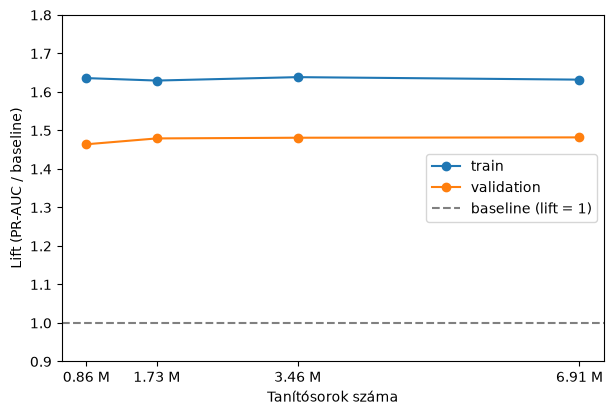

In [17]:
fig, ax = plt.subplots(figsize=(7, 4.5))

ax.plot(df["Train_Rows"], df["train_lift"], marker="o", label="train")
ax.plot(df["Train_Rows"], df["val_lift"], marker="o", label="validation")
ax.axhline(1.0, linestyle="--", color="gray", label="baseline (lift = 1)")

ax.set_xticks(df["Train_Rows"])
ax.set_xticklabels([f"{r / 1e6:.2f} M" for r in df["Train_Rows"]])


ax.set_ylim(0.9, 1.8)
ax.set_xlabel("Tanítósorok száma")
ax.set_ylabel("Lift (PR-AUC / baseline)")
ax.legend()

plt.show()

In [27]:
out = Path("../docs/figures/learning_curve_y1_4feat.png")
out.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(out, dpi=200, bbox_inches="tight")

## Hyperparameter change for diagnosis

`max_depth` = None
`min_samples_leaf` = 5
`n_estimators` = 20



In [28]:
diag = get_client().query_df(
    "SELECT Train_Rows, val_lift, train_lift FROM experiment_results "
    "WHERE Model_Name = 'rf_delay_y1_f25_t20_loose'"
)

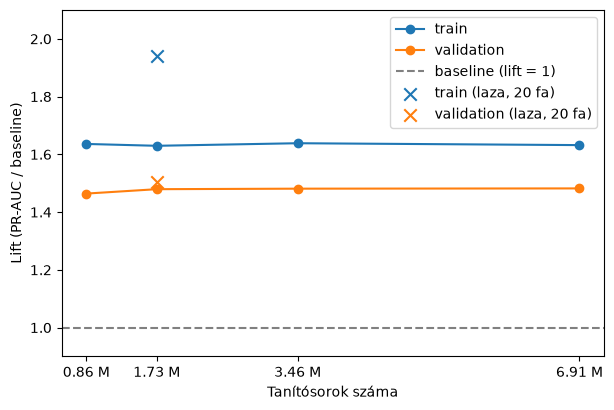

In [29]:
fig, ax = plt.subplots(figsize=(7, 4.5))

ax.plot(df["Train_Rows"], df["train_lift"], marker="o", label="train")
ax.plot(df["Train_Rows"], df["val_lift"], marker="o", label="validation")
ax.axhline(1.0, linestyle="--", color="gray", label="baseline (lift = 1)")

ax.set_xticks(df["Train_Rows"])
ax.set_xticklabels([f"{r / 1e6:.2f} M" for r in df["Train_Rows"]])


ax.set_ylim(0.9, 2.1)  
ax.set_xlabel("Tanítósorok száma")
ax.set_ylabel("Lift (PR-AUC / baseline)")

ax.scatter(diag["Train_Rows"], diag["train_lift"], marker="x", s=80,
           color="tab:blue", label="train (laza, 20 fa)")
ax.scatter(diag["Train_Rows"], diag["val_lift"], marker="x", s=80,
           color="tab:orange", label="validation (laza, 20 fa)")
ax.legend()

plt.show()

In [30]:
out = Path("../docs/figures/learning_curve_y1_4feat_loose.png")
out.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(out, dpi=200, bbox_inches="tight")

## Export

Save the figure for the thesis text.